In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option('display.max_rows', 30)
file_path = Path('season-2526.csv')
if not file_path.exists():
    raise FileNotFoundError('Put season-2526.csv in the same folder as this notebook.')
raw = pd.read_csv(file_path)
print('Original data:', raw.shape[0], 'matches and', raw.shape[1], 'columns')
display(raw.head())

Original data: 380 matches and 22 columns


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0


In [2]:
required = ['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HS', 'AS', 'HST', 'AST']
assert set(required).issubset(raw.columns), 'The CSV is missing expected columns.'
assert not raw[required].isna().any().any(), 'Missing values were found.'
assert not raw.duplicated(['Date', 'HomeTeam', 'AwayTeam']).any(), 'Duplicate matches found.'
assert raw[['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST']].ge(0).all().all()
assert (raw['HST'] <= raw['HS']).all() and (raw['AST'] <= raw['AS']).all()
assert raw['FTR'].isin(['H', 'D', 'A']).all()
print('Input checks passed.')

Input checks passed.


In [3]:
# Aggregate match statistics into one row per club
# For a home game, the home team's goals and shots are its for values; for an away game the away team's goals and shots are its for values. Convert each match into two team-level records, then total by club.

home = pd.DataFrame({
    'Team': raw['HomeTeam'],
    'Goals_For': raw['FTHG'],
    'Goals_Against': raw['FTAG'],
    'SOT_For': raw['HST'],
    'SOT_Against': raw['AST'],
    'Win': (raw['FTR'] == 'H').astype(int),
    'Draw': (raw['FTR'] == 'D').astype(int)
})
away = pd.DataFrame({
    'Team': raw['AwayTeam'],
    'Goals_For': raw['FTAG'],
    'Goals_Against': raw['FTHG'],
    'SOT_For': raw['AST'],
    'SOT_Against': raw['HST'],
    'Win': (raw['FTR'] == 'A').astype(int),
    'Draw': (raw['FTR'] == 'D').astype(int)
})
team_games = pd.concat([home, away], ignore_index=True)
teams = team_games.groupby('Team', as_index=False).agg(
    Matches=('Goals_For', 'size'),
    Goals_For=('Goals_For', 'sum'),
    Goals_Against=('Goals_Against', 'sum'),
    SOT_For=('SOT_For', 'sum'),
    SOT_Against=('SOT_Against', 'sum'),
    Wins=('Win', 'sum'),
    Draws=('Draw', 'sum')
)
teams['Points'] = teams['Wins'] * 3 + teams['Draws']
for stat in ['Goals_For', 'Goals_Against', 'SOT_For', 'SOT_Against']:
    teams[stat + '_per_match'] = teams[stat] / teams['Matches']
teams['Goal_Difference'] = teams['Goals_For'] - teams['Goals_Against']

assert len(raw) == 380 and len(teams) == 20
assert (teams['Matches'] == 38).all()
assert teams['Goals_For'].sum() == teams['Goals_Against'].sum()
assert teams['Matches'].sum() == 2 * len(raw)
print('All teams have 38 matches; league-wide goals balance.')
display(teams.sort_values('Points', ascending=False)[['Team','Matches','Points','Goals_For','Goals_Against','SOT_For','SOT_Against']])

All teams have 38 matches; league-wide goals balance.


,Team,Matches,Points,Goals_For,Goals_Against,SOT_For,SOT_Against
0,Arsenal,38,85,71,27,186,90
12,Man City,38,78,77,35,205,127
13,Man United,38,71,69,50,216,141
1,Aston Villa,38,65,56,49,170,168
11,Liverpool,38,60,63,53,175,153
2,Bournemouth,38,57,58,54,178,162
16,Sunderland,38,54,42,48,126,167
3,Brentford,38,53,55,52,147,162
4,Brighton,38,53,52,46,176,148
9,Fulham,38,52,47,51,138,149


In [6]:
# Scale four attacking/defensive features
# Each feature is a per-match rate. Standardization makes each feature contribute comparably to Euclidean distance. Points are reserved for later interpretation; they are not inputs to clustering.

features = [
    'Goals_For_per_match',
    'Goals_Against_per_match',
    'SOT_For_per_match',
    'SOT_Against_per_match'
]
scaler = StandardScaler()
X = scaler.fit_transform(teams[features])
print('Features used:', features)

Features used: ['Goals_For_per_match', 'Goals_Against_per_match', 'SOT_For_per_match', 'SOT_Against_per_match']


C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,k,Inertia,Silhouette
0,2,41.676,0.532
1,3,21.380,0.500
2,4,14.306,0.389
3,5,10.126,0.360
4,6,8.142,0.326
5,7,6.511,0.312


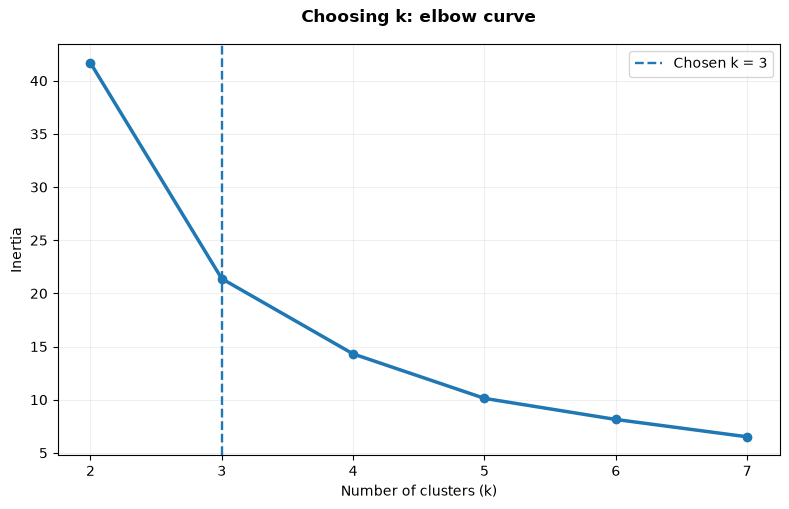

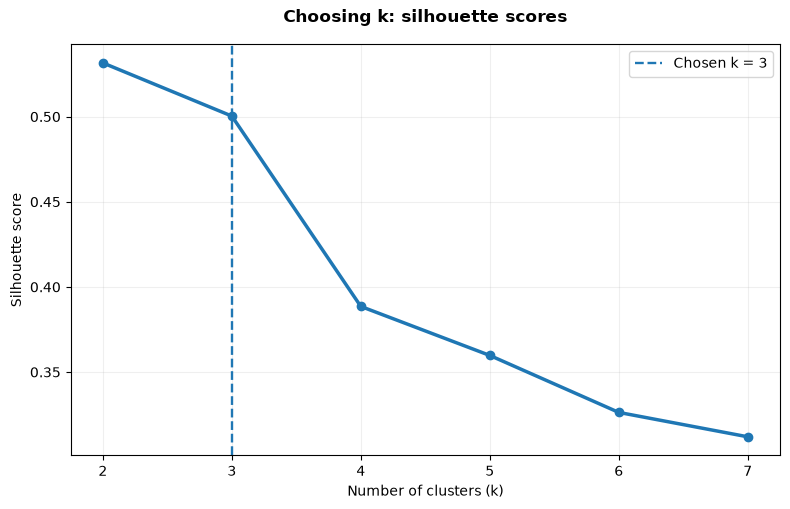

In [7]:
# Compare k values with inertia and silhouette scores
# Low inertia indicates tight clusters, but it always decreases as k grows. The silhouette score helps compare separation (higher is generally better).

evaluation = []
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = model.fit_predict(X)
    evaluation.append({
        'k': k,
        'Inertia': model.inertia_,
        'Silhouette': silhouette_score(X, labels)
    })
evaluation = pd.DataFrame(evaluation)
display(evaluation.round(3))

def setup_plot(title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(8, 5.2))
    ax.set_title(title, fontweight='bold', pad=16)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    return fig, ax

fig, ax = setup_plot('Choosing k: elbow curve', 'Number of clusters (k)', 'Inertia')
ax.plot(evaluation['k'], evaluation['Inertia'], marker='o', linewidth=2.5)
ax.axvline(3, linestyle='--', linewidth=1.7, label='Chosen k = 3')
ax.legend()
fig.tight_layout()
fig.savefig('epl_kmeans_elbow.png', dpi=200, bbox_inches='tight')
plt.show()

fig, ax = setup_plot('Choosing k: silhouette scores', 'Number of clusters (k)', 'Silhouette score')
ax.plot(evaluation['k'], evaluation['Silhouette'], marker='o', linewidth=2.5)
ax.axvline(3, linestyle='--', linewidth=1.7, label='Chosen k = 3')
ax.legend()
fig.tight_layout()
fig.savefig('epl_kmeans_silhouette.png', dpi=200, bbox_inches='tight')
plt.show()

In [8]:
model = KMeans(n_clusters=3, random_state=42, n_init=30)
teams['Cluster_ID'] = model.fit_predict(X)
means = teams.groupby('Cluster_ID')[['Goals_For_per_match','Goals_Against_per_match']].mean()
ranked_ids = (means['Goals_For_per_match'] - means['Goals_Against_per_match']).sort_values().index
cluster_names = {
    ranked_ids[0]: 'Struggling',
    ranked_ids[1]: 'Middle',
    ranked_ids[2]: 'Strong'
}
teams['Cluster'] = teams['Cluster_ID'].map(cluster_names)
order = ['Strong','Middle','Struggling']
summary = teams.groupby('Cluster').agg(
    Teams=('Team', 'size'),
    Goals_Scored_per_Match=('Goals_For_per_match','mean'),
    Goals_Allowed_per_Match=('Goals_Against_per_match','mean'),
    Shots_on_Target_For_per_Match=('SOT_For_per_match','mean'),
    Shots_on_Target_Against_per_Match=('SOT_Against_per_match','mean'),
    Avg_League_Points=('Points','mean')
).reindex(order)
print('Club groups:')
for c in order:
    names = teams.loc[teams['Cluster'] == c, 'Team'].sort_values().tolist()
    print(f'{c} ({len(names)}): ' + ', '.join(names))
print('\nCluster averages:')
display(summary.round(3))

teams.sort_values(['Cluster','Points'],ascending=[True,False]).to_csv('premier_league_team_clusters.csv',index=False)
summary.round(4).to_csv('premier_league_cluster_summary.csv')

Club groups:
Strong (3): Arsenal, Man City, Man United
Middle (14): Aston Villa, Bournemouth, Brentford, Brighton, Chelsea, Crystal Palace, Everton, Fulham, Leeds, Liverpool, Newcastle, Nott'm Forest, Sunderland, Tottenham
Struggling (3): Burnley, West Ham, Wolves

Cluster averages:


C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Teams,Goals_Scored_per_Match,Goals_Allowed_per_Match,Shots_on_Target_For_per_Match,Shots_on_Target_Against_per_Match,Avg_League_Points
Cluster,,,,,,
Strong,3,1.904,0.982,5.325,3.140,78.0
Middle,14,1.348,1.363,4.120,4.201,51.5
Struggling,3,0.974,1.825,3.360,5.167,27.0


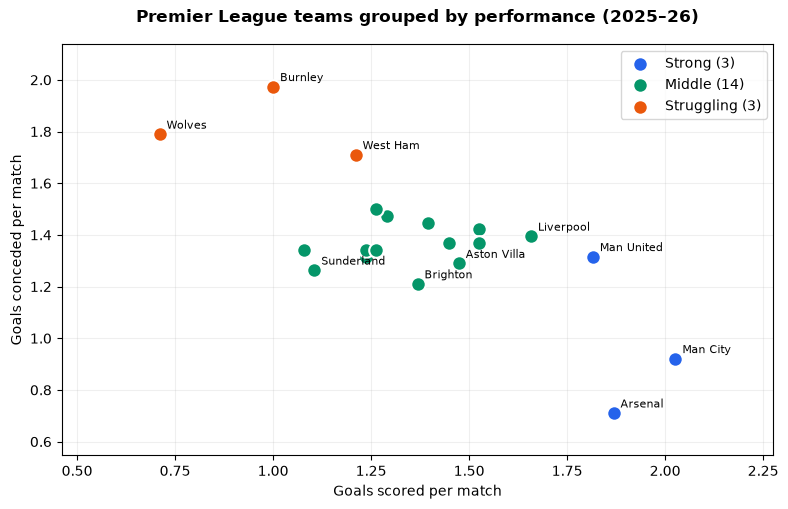

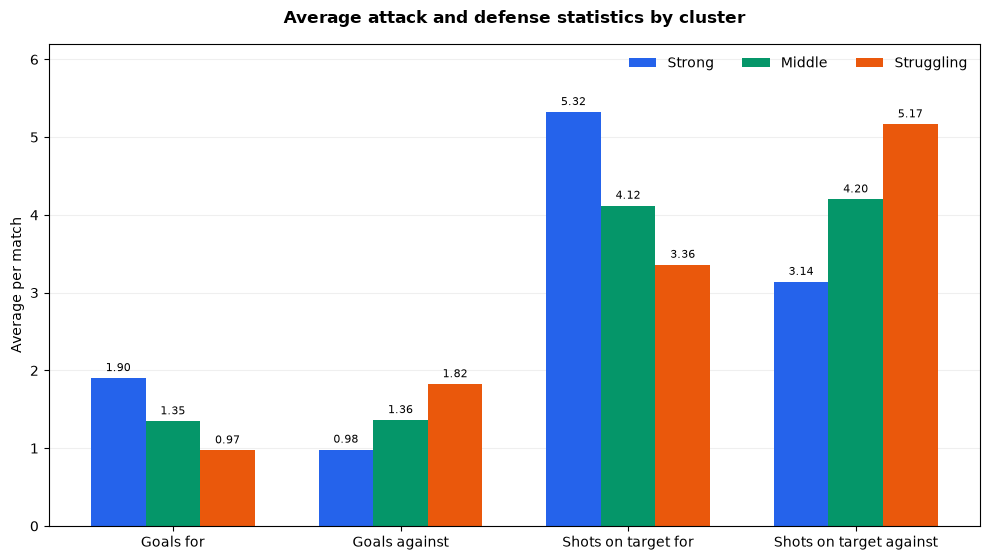

In [9]:
colors = {'Strong':'#2563eb', 'Middle':'#059669', 'Struggling':'#ea580c'}
fig, ax = setup_plot('Premier League teams grouped by performance (2025–26)',
                     'Goals scored per match', 'Goals conceded per match')
labeled_examples = {'Arsenal','Man City','Man United','Liverpool',
                    'Aston Villa','Brighton','Sunderland','West Ham','Burnley','Wolves'}
for cluster in order:
    g = teams[teams['Cluster'] == cluster]
    ax.scatter(g['Goals_For_per_match'],g['Goals_Against_per_match'],
               s=110,color=colors[cluster],label=f'{cluster} ({len(g)})',zorder=3,
               edgecolor='white',linewidth=1.5)
    for _,r in g.iterrows():
        if r['Team'] not in labeled_examples:
            continue
        name = r['Team'].replace("Nott'm Forest",'Nottingham F.')
        ax.annotate(name,(r['Goals_For_per_match'],r['Goals_Against_per_match']),
                    xytext=(5,4),textcoords='offset points',fontsize=7.6)
ax.legend(loc='upper right')
ax.margins(x=0.19,y=0.13)
fig.tight_layout()
fig.savefig('epl_clusters_scatter.png',dpi=240,bbox_inches='tight')
plt.show()

profile_cols=['Goals_Scored_per_Match','Goals_Allowed_per_Match',
              'Shots_on_Target_For_per_Match','Shots_on_Target_Against_per_Match']
profile_labels=['Goals for','Goals against','Shots on target for','Shots on target against']
fig, ax = plt.subplots(figsize=(10,5.7))
xpos=np.arange(len(profile_cols));bar_width=0.24
for i,cluster in enumerate(order):
    vals=summary.loc[cluster,profile_cols].to_numpy(dtype=float)
    bars=ax.bar(xpos+(i-1)*bar_width,vals,width=bar_width,label=cluster,color=colors[cluster])
    ax.bar_label(bars,fmt='%.2f',padding=3,fontsize=8)
ax.set_title('Average attack and defense statistics by cluster',fontweight='bold',pad=15)
ax.set_ylabel('Average per match')
ax.set_xticks(xpos,profile_labels)
ax.set_ylim(0,6.2)
ax.legend(frameon=False,ncol=3)
ax.grid(axis='y',alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig('epl_cluster_profiles.png',dpi=220,bbox_inches='tight')
plt.show()

In [10]:
reference_labels = teams['Cluster_ID'].to_numpy()
seeds = [0, 1, 4, 7, 12, 42]
stability = []
for seed in seeds:
    alternative = KMeans(n_clusters=3, n_init=30, random_state=seed).fit_predict(X)
    stability.append(adjusted_rand_score(reference_labels, alternative))
print('Adjusted Rand indices against the main run:')
print(dict(zip(seeds,[round(v,3) for v in stability])))
assert all(np.isclose(v,1.0) for v in stability)
print('Validation passed. Saved files:')
for p in ['premier_league_team_clusters.csv','premier_league_cluster_summary.csv',
          'epl_kmeans_elbow.png','epl_kmeans_silhouette.png',
          'epl_clusters_scatter.png','epl_cluster_profiles.png']:
    print(' -',p)

C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Adjusted Rand indices against the main run:
{0: 1.0, 1: 1.0, 4: 1.0, 7: 1.0, 12: 1.0, 42: 1.0}
Validation passed. Saved files:
 - premier_league_team_clusters.csv
 - premier_league_cluster_summary.csv
 - epl_kmeans_elbow.png
 - epl_kmeans_silhouette.png
 - epl_clusters_scatter.png
 - epl_cluster_profiles.png


C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\5cruz\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
